# Find geographic sources of dose-respone function differences

Look at marginal changes in dose-response functions

In [1]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import re
import glob
import string
import zarr
import warnings
from tqdm.notebook import tqdm

import matplotlib as mpl
from matplotlib import pyplot as plt
import cmocean
from cartopy import crs as ccrs

from funcs_support import get_filepaths,get_params,utility_save,utility_print,load_shp
from funcs_readregs import coeffs_mortality, coeffs_gdppc, coeffs_payroll

dir_list = get_params()



In [2]:
from distributed import Client

# Start dask client
client = Client()
display(client)

/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 45251 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc3/proxy/45251/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc3/proxy/45251/status,Workers: 6
Total threads: 18,Total memory: 72.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:44471,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc3/proxy/45251/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:38589,Total threads: 3
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc3/proxy/46453/status,Memory: 12.00 GiB
Nanny: tcp://127.0.0.1:34499,


In [3]:
nsamples = 1000
rng = np.random.default_rng()

def load_dmgfs(proc,load_kwargs = {},
              rng = rng,
              nsamples = nsamples):
    ''' Load MC'ed damage function, sampled at temperatures Tref

    Parameters
    ---------------
    proc : str
        Name of impact variable

    load_kwargs : dict
        Piped into `coeffs_*()`

    rng : numpy random generator

    nsamples : int
        Number of MC samples of VCV to use

    Returns
    ---------------
    dmgf : xr.DataArray
        `Tref` x `proj_base` x `sidx` datarray giving 
        coefficients at temperatures `Tref`


    '''
    
    # Load regression coefficients
    if proc == 'gdppc':
        coeffs,vcv = coeffs_gdppc(**load_kwargs)
    elif proc == 'mortality':
        coeffs,vcv = coeffs_mortality(**load_kwargs)
    elif proc == 'payroll':
        coeffs,vcv = coeffs_payroll(**load_kwargs)
    else:
        raise KeyError()

    coeffs = coeffs.dropna('proj_base',how='all')
    if 'proj_base_1' in vcv:
        vcv.dropna('proj_base_1').dropna('proj_base_2')
    else:
        vcv = vcv.dropna('proj_base',how='all')

    # Get MC samples of coefficients
    if 'proj_base_1' in vcv:
        # If jointly estimated across parameters
        coeffs_tmp = coeffs.coeffs.stack(predproj = ['pred','proj_base'])
        vcv_tmp = vcv.vcv.stack(predproj_1 = ['pred_1','proj_base_1'],
                                 predproj_2 = ['pred_2','proj_base_2'])
        
        coeffs_mvn = rng.multivariate_normal(coeffs_tmp,
                                             vcv_tmp,
                                             size=nsamples)
        
        coeffs_mvn = xr.DataArray(coeffs_mvn,
                                  dims = ['sidx','predproj'],
                                  coords = {'predproj':coeffs_tmp.predproj})
        coeffs_mvn = coeffs_mvn.unstack('predproj')
    else:
        # If separate fit for each proj_base
        coeffs_mvn = xr.apply_ufunc(rng.multivariate_normal,
                                   coeffs.coeffs,
                                   vcv.vcv,
                                   input_core_dims = [['pred'],['pred_1','pred_2']],
                                   output_core_dims = [['sidx','pred']],
                                   kwargs = {'size':nsamples},
                                           dask = 'parallelized',
                                           dask_gufunc_kwargs = {'output_sizes':{'sidx':nsamples}},
                                   vectorize=True)

    if np.any(['sumpoly' in k for k in coeffs_mvn.pred.values]):
        ts = np.arange(-20,51)
        var_stem = 'tassumpoly_'
        poly_degs = [int(re.split(var_stem,v)[-1]) for v in coeffs_mvn.pred.values if var_stem in v]
        t_vals = xr.DataArray(np.vstack([ts**k for k in poly_degs]),
                     dims = ['pred','bin_c'],
                     coords = {'pred':[v for v in coeffs_mvn.pred.values if var_stem in v],
                               'bin_c':ts})
    
        # Get damage function
        dmgf = (coeffs_mvn*t_vals).sum('pred')
        
        if proc == 'mortality':
            # Normalize over lowest value
            dmgf = dmgf - dmgf.sel(bin_c = slice(10,30)).min('bin_c')
        elif proc == 'gdppc':
            # Normalize over highest value
            dmgf = dmgf - dmgf.sel(bin_c = slice(10,30)).max('bin_c')
            #dmgf = dmgf - dmgf.sel(bin_c = 13)
        
        dmgf = dmgf.rename({'bin_c':'Tref'})
    elif 'bin' in coeffs_mvn.pred.values[0]:
        # Constructing the single-bin version
        dmgf = xr.apply_ufunc(rng.normal,
                   coeffs.isel(pred=0),
                   vcv.vcv.isel(pred_1 = 0,pred_2 = 0),
                   output_core_dims = [['sidx']],
                   vectorize=True,
                   kwargs = {'size':nsamples})
        
        dmgf = dmgf.expand_dims({'bin_f':np.arange(float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1]),
                                             125,5)})
        
        dmgf = xr.concat([xr.zeros_like(dmgf.isel(bin_f=0,drop=True)).expand_dims({'bin_f':np.arange(float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1])-20,
                                                                                   float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1]),
                                                                                   5)}),
                          dmgf],
                         dim='bin_f')
    
        dmgf = dmgf.rename({'bin_f':'Tref'}).coeffs
    elif 'days' in coeffs_mvn.pred.values[0]:
        dmgf = coeffs_mvn.expand_dims({'bin_f':np.arange(92.5, 125,5)}).isel(pred=0)
        dmgf = xr.concat([xr.zeros_like(dmgf.isel(bin_f=0,drop=True)).expand_dims({'bin_f':np.arange(92.5-20,
                                                                                           92.5,
                                                                                           5)}),
                                  dmgf],
                                 dim='bin_f')
        dmgf = dmgf.rename({'bin_f':'Tref'})

    return dmgf

## Start of new

In [4]:
dfr = get_filepaths()
joint_years = [1980,2010]

In [5]:
dss = {}
coeffs = {}
vcv = {}
dmes = {}
gdfs = {}

### Mortality

In [5]:
# Get in-sample data that's feeding the regressions
# (we're using this only to get population by year by location)
reg_data = pd.read_csv(dir_list['proc']+'reg_inputs/mortality/reginputs_mortality_025deg.csv',low_memory=False,index_col=0)
reg_data = reg_data.query('iso != "IND" and iso != "CHN" and iso != "USA"')
reg_data = reg_data.query('agegroup == "total"')
# Subset to any of them (since only getting population, which is the
# same for all reanalyses of course)
reg_data = reg_data.query('obs_mod == "GMFD"')
reg_data['regid'] = reg_data['iso']+reg_data['adm1_id']+reg_data['adm2_id']
reg_data = reg_data.query(f'(year >= {joint_years[0]}) and (year <= {joint_years[1]})')

# This is the leave-one-out level
reg_data['loo_id'] = reg_data['adm0']+reg_data['adm1_id']
#df = df.loc[:,['iso','adm0','adm1_id','adm2_id','loo_id','adm1','adm2']].drop_duplicates()

In [104]:
# Load shapefile used for create_reginputs
gdfs['mortality'] = gpd.read_file(dir_list['aux']+'geo_data/mortality_insample_world_wadm0.shp')
gdfs['mortality']['loo_id'] = gdfs['mortality']['adm0']+gdfs['mortality']['adm1_id']
gdfs['mortality']['regid'] = gdfs['mortality']['iso']+gdfs['mortality']['adm1_id']+gdfs['mortality']['adm2_id']


In [93]:
joint_years = [1980,2010]

output_fn = f'{dir_list['proc']}tmp/dmgfdiffs_sources_tmp_mortality.zarr'

if not os.path.exists(output_fn):
    dss = []
    for mod in ['ERA5-025','MERRA2','JRA-3Q','GMFD']:
        print('Processing '+mod+'...')
        dfr_tmp = dfr.query('model == "'+mod+'" and varname == "tas" and freq == "day"')
        ds = xr.open_dataset(dfr_tmp.iloc[0]['path'],chunks='auto')
    
        # Subset to joint years
        ds = ds.sel(time=slice(str(joint_years[0]),str(joint_years[1])))
    
        # Aggregate to polygons
        wm = xa.pixel_overlaps(ds,gdfs['mortality'])
        with xa.set_options(impl='numba',silent=True):
            aggs = xa.aggregate(ds.chunk({'lat':-1,'lon':-1}),wm)
    
        aggs = aggs.to_dataset()
        aggs = aggs.set_coords([v for v in aggs if v != 'tas'])
        aggs = aggs.expand_dims({'mod':[mod]})
        #aggs = aggs.assign_coords({'poly_idx':aggs.iso+aggs.adm1_id+aggs.adm2_id})
        aggs = aggs.assign_coords({'poly_idx':'regid'})
    
        aggs['time'] = pd.date_range(str(joint_years[0])+'-01-01',str(joint_years[1])+'-12-31')
        dss.append(aggs)

    dss = xr.concat(dss,dim='mod',data_vars='different').rename({'mod':'proj_base'})

    # K to C
    dss['tas'] = dss['tas']-273.15
    # ERA5-025 to ERA5
    dss['proj_base'] = [re.sub(r'\-025','',pb) for pb in dss['proj_base'].values]

    reg_data_merge = reg_data[['year','regid','loo_id','population']]
    reg_data_merge = reg_data_merge.drop_duplicates().set_index(['year','regid'])
    
    # To xarray, assigning population to each timestep by its yearly value
    reg_data_merge = reg_data_merge.to_xarray().sel(year = dss.time.dt.year)
    reg_data_merge = reg_data_merge.drop_vars('year')

    dss = xr.merge([dss,reg_data_merge[['population']]],join='inner')

    dss.attrs = {'SOURCE':'3b_dmgfdiffs_sources.ipynb',
             'DESCRIPTION':'Temperature, population for ME comparisons'}

    dss = dss.chunk({'proj_base':-1,'time':3650,'regid':1000})
    utility_save(dss,output_fn)
else:
    print(output_fn+' exists, loading...')

dss['mortality'] = xr.open_zarr(output_fn)
for v in dss['mortality'].coords:
    dss['mortality'][v] = dss['mortality'][v].load()

/glade/derecho/scratch/schwarzwald/impact_uncertainty/tmp/dmgfdiffs_sources_tmp_mortality.zarr exists, loading...


In [8]:
output_fn = f'{dir_list['proc']}tmp/dmgfdiffs_bcdrun_tmp_mortality.zarr'

gdf_impregs = load_shp('mortality')

if not os.path.exists(output_fn):
    # Now, get tas (1-deg, for time series) for one random BCD-ME member, as illustration
    fn = glob.glob(dir_list['bcd_me']+'/*qdm_*CanESM5*')[0]
    ds_bcd = xr.open_zarr(fn,decode_timedelta=False,consolidated=False)
    has_data = ds_bcd.has_data.sel(gwl=2,variable='tas').load()
    has_data = np.where(has_data)[0]
    ds_bcd = ds_bcd.isel(idv = has_data[0])['tas'].sel(gwl=2)
    ds_bcd = ds_bcd.chunk({'lat':-1,'lon':-1,'year':1})
    #ds_bcd = ds_bcd.sel(proj_base = ['ERA5','GMFD','JRA-3Q','MERRA2']).load()


    # Aggregate to polygons
    wm = xa.pixel_overlaps(ds_bcd,gdf_impregs)
    with xa.set_options(impl='numba',silent=True):
        #aggs = xa.aggregate(ds_bcd.chunk({'lat':-1,'lon':-1}),wm)
        aggs = xa.aggregate(ds_bcd,wm)

    aggs = aggs.to_dataset()
    aggs = aggs.set_coords([v for v in aggs if v != 'tas'])
    aggs['poly_idx'] = aggs['locid'].values
    aggs = aggs.drop_vars('locid').rename({'poly_idx':'locid'})

    aggs['tas'] = aggs['tas'] - 273.15
    aggs = aggs.stack(time=['year','dayofyear'])

    aggs.attrs = {'SOURCE':'3b_dmgfdiffs_sources.ipynb',
             'DESCRIPTION':'Future temperature from a random BCD-ME run for ME comparisons'}

    aggs = aggs.chunk({'proj_base':-1,'time':3650,'locid':1000})
    utility_save(aggs.reset_index('time'),output_fn)
else:
    print(output_fn+' exists, loading...')

dss_bcd = xr.open_zarr(output_fn)
for v in dss_bcd.coords:
    dss_bcd[v] = dss_bcd[v].load()

/glade/derecho/scratch/schwarzwald/impact_uncertainty/tmp/dmgfdiffs_bcdrun_tmp_mortality.zarr exists, loading...


In [94]:
# Now, get regression coefficients from the leave-one-out regressions
coeffs['mortality'],vcv['mortality'] = coeffs_mortality(get_loos=True)
coeffs_all,vcv_all = coeffs_mortality()

# Also add the reference / "all" locations regression
coeffs_all = coeffs_all.expand_dims({'loo_id':['all']})
vcv_all = vcv_all.expand_dims({'loo_id':['all']})

coeffs['mortality'] = xr.concat([coeffs['mortality'],coeffs_all],dim='loo_id')
vcv['mortality'] = xr.concat([vcv['mortality'],vcv_all],dim='loo_id')

In [6]:
def mes_mortality(coeffs,T):
    me = (coeffs.sel(pred='tassumpoly_1') + 
          2*coeffs.sel(pred='tassumpoly_2')*T + 
          3*coeffs.sel(pred='tassumpoly_3')*(T**2) + 
          4*coeffs.sel(pred='tassumpoly_4')*(T**3))
    return me

def mes_gdppc(coeffs,T):
    me = (coeffs.sel(pred='tassumpoly_1') + 
          2*coeffs.sel(pred='tassumpoly_2')*T)
    return me

In [33]:
#------ Setup
# Ensure that differences between each combination of 
# proj_bases is only done once to avoid double-processing
# (little silly, but gets the job done)
joint_mask = xr.DataArray(0,
                 dims = ['proj_base_a','proj_base_b'],
               coords = {'proj_base_a':(('proj_base_a'),coeffs['gdppc'].proj_base.values),
                       'proj_base_b':(('proj_base_b'),coeffs['gdppc'].proj_base.values)})
for i in range(joint_mask.sizes['proj_base_a']):
    for j in range(joint_mask.sizes['proj_base_b']):
        if j < i:
            joint_mask[{'proj_base_a':i,'proj_base_b':j}] = 1

keep_pairs = joint_mask.where(joint_mask).stack(pb_pairs = ['proj_base_a','proj_base_b']).dropna(dim='pb_pairs').pb_pairs.values

In [41]:
dss = dss['gdppc']
coeffs = coeffs['gdppc']

In [53]:
loo_id_tmp = coeffs.loo_id.values[0]
no_loo_subset = False

if (loo_id_tmp == 'all') or (no_loo_subset):
    dist_tmp = dss.copy()
else:
    dist_tmp = dss.where(dss.loo_id != loo_id_tmp,drop=True)

# Get joint distribution for each combination of reanalyses
# (the distribution is now over the dimension "time") 
dist_tmp = xr.concat([dist_tmp.rename({'proj_base':'proj_base_a'}),
           dist_tmp.rename({'proj_base':'proj_base_b'})],
          dim='time')

# Get coefficients for each reanalysis fit
coeffs_tmp = coeffs.sel(loo_id = loo_id_tmp)
# Expand coefficients into a/b pairs for ease of processing
# (i.e., for each renalysis a,b, store the coefficients in an 
# easy pair)
coeffs_tmp = xr.concat([coeffs_tmp.rename({'proj_base':'proj_base_a'}).expand_dims({'proj_base_b':coeffs_tmp.proj_base.values}).coeffs,
                         coeffs_tmp.rename({'proj_base':'proj_base_b'}).expand_dims({'proj_base_a':coeffs_tmp.proj_base.values}).coeffs],
          dim=pd.Index(['a','b'],name='pb_idx'))

# Merge
with warnings.catch_warnings():
    # FutureWarning about compat default change... 
    warnings.filterwarnings('ignore')
    dist_tmp = xr.merge([dist_tmp.drop_vars('loo_id',errors='ignore'),coeffs_tmp],join='outer')

# Make the diagonals as well as the duplicates nan (i.e., keep
# only one side of off-diagonals
#dist_tmp = dist_tmp.where(joint_mask)
#dist_tmp = dist_tmp.stack(pb_pairs = ['proj_base_a','proj_base_b']).sel(pb_pairs = keep_pairs)

In [54]:
dist_tmp

<xarray.Dataset> Size: 3MB
Dimensions:      (locid: 194, year: 31, proj_base_a: 6, proj_base_b: 6,
                  time: 2, pred: 2, pb_idx: 2)
Coordinates:
  * locid        (locid) object 2kB 'Albania' 'Algeria' ... 'Zambia' 'Zimbabwe'
  * year         (year) int64 248B 1980 1981 1982 1983 ... 2007 2008 2009 2010
  * proj_base_a  (proj_base_a) object 48B 'ERA5' 'ERA5-025' ... 'MERRA2' 'UDel'
  * proj_base_b  (proj_base_b) object 48B 'ERA5' 'ERA5-025' ... 'MERRA2' 'UDel'
  * pred         (pred) object 16B 'tassumpoly_1' 'tassumpoly_2'
  * pb_idx       (pb_idx) object 16B 'a' 'b'
    resolution   <U6 24B '025deg'
    timeframe    <U9 36B '1980-2010'
    obstreat     <U3 12B 'sep'
    loo_id       <U11 44B 'Afghanistan'
Dimensions without coordinates: time
Data variables:
    tas          (time, locid, year, proj_base_a, proj_base_b) float64 3MB na...
    coeffs       (pb_idx, proj_base_b, pred, proj_base_a) float64 1kB 0.0157 ...

In [7]:
def calc_dmes(dss,coeffs,weight_var = 'population',me_func = mes_mortality,climvar='tas',no_loo_subset=False):
    ''' Calc mean absolute differences in marginal effects from leave-one-out experiments
    For each combination of 2 reanalyses, 
      for each set of coefficients calculated leaving one out: 
    - Get the joint distribution over combination of reanalysis values (or
      reanalysis ground truths) as the combined `dss` values for both 
      `proj_base` inputs
    - Get the absolute difference between the marginal effects set by `coeffs`
      at each of those temperature values 
    - Get the average of those absolute differences over the whole joint 
      distribution (i.e., over time and space), possibly weighted by `weight_var`

    Parameters
    -----------------


    weight_var : str or None
    '''
    #------ Setup
    # Ensure that differences between each combination of 
    # proj_bases is only done once to avoid double-processing
    # (little silly, but gets the job done)
    joint_mask = xr.DataArray(0,
                     dims = ['proj_base_a','proj_base_b'],
                   coords = {'proj_base_a':(('proj_base_a'),coeffs.proj_base.values),
                           'proj_base_b':(('proj_base_b'),coeffs.proj_base.values)})
    for i in range(joint_mask.sizes['proj_base_a']):
        for j in range(joint_mask.sizes['proj_base_b']):
            if j < i:
                joint_mask[{'proj_base_a':i,'proj_base_b':j}] = 1
    
    keep_pairs = joint_mask.where(joint_mask).stack(pb_pairs = ['proj_base_a','proj_base_b']).dropna(dim='pb_pairs').pb_pairs.values


    #------ Process
    dmes_int_all = []

    for loo_id_tmp in tqdm(coeffs.loo_id): 
    
        if (loo_id_tmp == 'all') or (no_loo_subset):
            dist_tmp = dss.copy()
        else:
            dist_tmp = dss.where(dss.loo_id != loo_id_tmp,drop=True)
        
        # Get joint distribution for each combination of reanalyses
        # (the distribution is now over the dimension "time") 
        dist_tmp = xr.concat([dist_tmp.rename({'proj_base':'proj_base_a'}),
                   dist_tmp.rename({'proj_base':'proj_base_b'})],
                  dim='time')
        
        # Get coefficients for each reanalysis fit
        coeffs_tmp = coeffs.sel(loo_id = loo_id_tmp)
        # Expand coefficients into a/b pairs for ease of processing
        # (i.e., for each renalysis a,b, store the coefficients in an 
        # easy pair)
        coeffs_tmp = xr.concat([coeffs_tmp.rename({'proj_base':'proj_base_a'}).expand_dims({'proj_base_b':coeffs_tmp.proj_base.values}).coeffs,
                                 coeffs_tmp.rename({'proj_base':'proj_base_b'}).expand_dims({'proj_base_a':coeffs_tmp.proj_base.values}).coeffs],
                  dim=pd.Index(['a','b'],name='pb_idx'))
        
        # Merge
        with warnings.catch_warnings():
            # FutureWarning about compat default change... 
            warnings.filterwarnings('ignore')
            dist_tmp = xr.merge([dist_tmp.drop_vars('loo_id',errors='ignore'),coeffs_tmp],join='outer')
        
        # Make the diagonals as well as the duplicates nan (i.e., keep
        # only one side of off-diagonals
        dist_tmp = dist_tmp.where(joint_mask)
        dist_tmp = dist_tmp.stack(pb_pairs = ['proj_base_a','proj_base_b']).sel(pb_pairs = keep_pairs)
        if weight_var is not None:
            # Issue with .where above, where it gets broadcast
            # THIS COULD LEAD TO ISSUES IF USED OUT OF SCOPE
            dist_tmp[weight_var] = dist_tmp[weight_var].isel(pb_pairs = 0,drop=True)
    
        # Get difference in marginal effects over every temperature in joint a-b sample 
        dmes = np.abs(me_func(dist_tmp['coeffs'].sel(pb_idx='a'),dist_tmp[climvar]) - 
                      me_func(dist_tmp['coeffs'].sel(pb_idx='b'),dist_tmp[climvar]))
        if weight_var is not None:
            # Integrate, weighing by population as in the original regression
            dmes_int = (dist_tmp[weight_var]*dmes).sum(['time','regid']) / dist_tmp[weight_var].sum(['time','regid'])
        else:
            dmes_int = dmes.mean(['time','regid'])
    
        # Compute
        dmes_int = dmes_int.compute()
        dmes_int_all.append(dmes_int)

    #------ Combine
    dmes_int_all = xr.concat(dmes_int_all,dim='loo_id')

    return dmes_int_all

In [72]:
# Raw GWL2 projection temperatures
dmes_int_all = calc_dmes(dss_bcd.rename({'locid':'regid'}),coeffs,weight_var=None,no_loo_subset=True)
dmes_int_all.unstack().to_netcdf(dir_list['aux']+'dmgf_diffs_mortality_bcdrun_meds_tmp.nc')

  0%|          | 0/247 [00:00<?, ?it/s]

In [77]:
# Pop-weighted input data temperatures
dmes_int_all = calc_dmes(dss,coeffs,weight_var='population',no_loo_subset=False)
dmes_int_all.unstack().to_netcdf(dir_list['aux']+'dmgf_diffs_mortality_meds_tmp.nc')

  0%|          | 0/247 [00:00<?, ?it/s]

In [97]:
dmes['mortality'] = {'input':xr.open_dataset(dir_list['aux']+'dmgf_diffs_mortality_meds_tmp.nc'),
                'future':xr.open_dataset(dir_list['aux']+'dmgf_diffs_mortality_bcdrun_meds_tmp.nc')}
for x in dmes['mortality']:
    dmes['mortality'][x] = dmes['mortality'][x].rename({'__xarray_dataarray_variable__':'dme'})
dmes['mortality'] = xr.concat([d for k,d in dmes['mortality'].items()],
                         dim=pd.Index([d for d in dmes['mortality']],name='typ'))

dmes['mortality']['dme_mu'] = dmes['mortality']['dme'].mean(('proj_base_a','proj_base_b'))
dmes['mortality']['dme_max'] = dmes['mortality']['dme'].max(('proj_base_a','proj_base_b'))

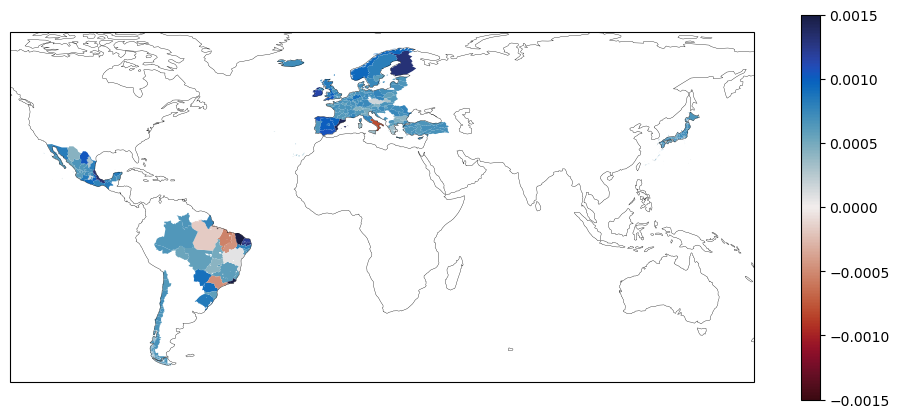

In [105]:
# Load shapefile used for create_reginputs
gdf_loo = gdfs['mortality'].dissolve(by='loo_id')
gdf_loo = gdf_loo.join((dmes['mortality'] - dmes['mortality'].sel(loo_id='all')).sel(typ='input')[['dme_mu','dme_max']].to_dataframe()[['dme_mu','dme_max']],
             how='inner')

fig = plt.figure(figsize=(12,5))
ax = plt.subplot(projection=ccrs.PlateCarree())

gdf_loo.plot(column='dme_max',legend=True,vmin=-0.00150,vmax=0.00150,cmap=cmocean.cm.balance_r,
             ax = ax,transform=ccrs.PlateCarree())
ax.coastlines(linewidth=0.25)

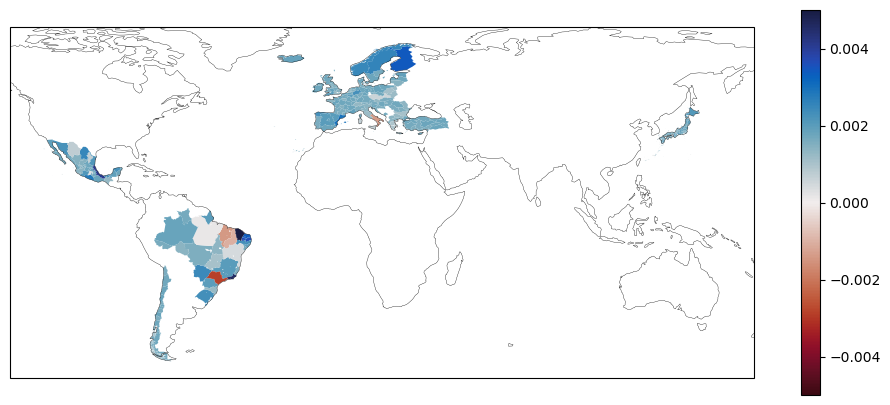

In [33]:
gdf_loo = gdf.dissolve(by='loo_id')
gdf_loo = gdf_loo.join((dmes_int_all - dmes_int_all.sel(loo_id='all')).sel(typ='future')[['dme_mu','dme_max']].to_dataframe()[['dme_mu','dme_max']],
             how='inner')

fig = plt.figure(figsize=(12,5))
ax = plt.subplot(projection=ccrs.PlateCarree())

gdf_loo.plot(column='dme_max',legend=True,vmin=-0.005,vmax=0.0050,cmap=cmocean.cm.balance_r,
             ax = ax,transform=ccrs.PlateCarree())
ax.coastlines(linewidth=0.25)

### GDP pc

In [138]:
gdfs['gdppc'] = load_shp('gdppc')
gdfs['gdppc']['loo_id'] = gdfs['gdppc']['locid']
dfr = get_filepaths()
joint_years = [1980,2010]

In [139]:
df_reg = pd.read_csv(dir_list['proc']+'reg_inputs/gdppc/reginputs_gdppc_025deg.csv')
df_reg = df_reg.where((df_reg['year']>=joint_years[0]) & (df_reg['year'].values<=joint_years[1])).dropna(how='all')
df_reg['year'] = df_reg['year'].astype(int)
df_reg = df_reg.set_index(['countryname','year','obs_mod'])[['temp_popweight']]

dss['gdppc'] = df_reg.to_xarray().rename({'countryname':'locid','obs_mod':'proj_base',
                           'temp_popweight':'tas'}).sortby('year')

dss['gdppc']['loo_id'] = (('locid'),dss['gdppc']['locid'].values)
dss['gdppc']['proj_base'] = [re.sub(r'\-025','',pb) for pb in dss['gdppc']['proj_base'].values]

In [140]:
# Now, get regression coefficients from the leave-one-out regressions
coeffs['gdppc'],vcv['gdppc'] = coeffs_gdppc(get_loos=True)
coeffs_all,vcv_all = coeffs_gdppc()

# Also add the reference / "all" locations regression
coeffs_all = coeffs_all.expand_dims({'loo_id':['all']})
vcv_all = vcv_all.expand_dims({'loo_id':['all']})

coeffs['gdppc'] = xr.concat([coeffs['gdppc'],coeffs_all],dim='loo_id')
vcv['gdppc'] = xr.concat([vcv['gdppc'],vcv_all],dim='loo_id')

In [141]:
# Input data temperatures
dmes_int_all = calc_dmes(dss['gdppc'].rename({'locid':'regid','year':'time'}),coeffs['gdppc'],weight_var=None,me_func=mes_gdppc)
dmes_int_all.unstack().to_netcdf(dir_list['aux']+'dmgf_diffs_gdppc_meds_tmp.nc')

  0%|          | 0/168 [00:00<?, ?it/s]

/glade/derecho/scratch/schwarzwald/tmp/ipykernel_127617/1553804860.py:47: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  dist_tmp = xr.concat([dist_tmp.rename({'proj_base':'proj_base_a'}),


In [142]:
dmes['gdppc'] = xr.open_dataset(dir_list['aux']+'dmgf_diffs_gdppc_meds_tmp.nc')
dmes['gdppc'] = dmes['gdppc'].rename({'__xarray_dataarray_variable__':'dme'})

dmes['gdppc']['dme_mu'] = dmes['gdppc']['dme'].mean(('proj_base_a','proj_base_b'))
dmes['gdppc']['dme_max'] = dmes['gdppc']['dme'].max(('proj_base_a','proj_base_b'))

(array([  80.,  190.,  292., 1736., 3397., 2614., 2312., 4043., 7133.,
        5663.]),
 array([-7.46062073e+00, -3.72711713e+00,  6.38648440e-03,  3.73989009e+00,
         7.47339370e+00,  1.12068973e+01,  1.49404009e+01,  1.86739045e+01,
         2.24074081e+01,  2.61409118e+01,  2.98744154e+01]),
 <BarContainer object of 10 artists>)

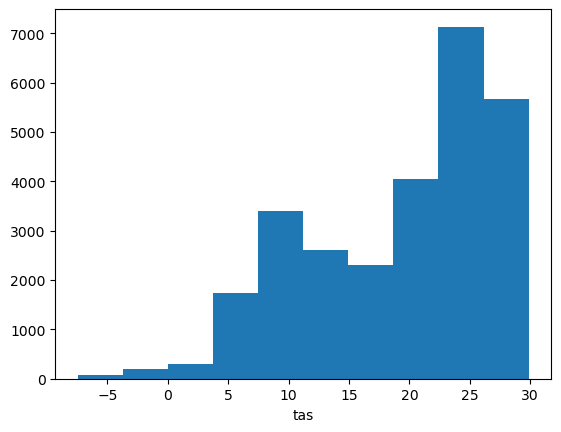

In [143]:
dss['gdppc'].tas.plot.hist()

In [144]:
ts = np.arange(-7.5,30)
var_stem = 'tassumpoly_'
poly_degs = [int(re.split(var_stem,v)[-1]) for v in coeffs['gdppc'].pred.values if var_stem in v]
t_vals = xr.DataArray(np.vstack([ts**k for k in poly_degs]),
             dims = ['pred','bin_c'],
             coords = {'pred':[v for v in coeffs['gdppc'].pred.values if var_stem in v],
                       'bin_c':ts})

# Get damage function
dmgf = (coeffs['gdppc']*t_vals).sum('pred')

dmgf = dmgf - dmgf.sel(bin_c = slice(10,30)).max('bin_c')
dmgf

<xarray.Dataset> Size: 257kB
Dimensions:     (proj_base: 5, loo_id: 168, bin_c: 38)
Coordinates:
  * proj_base   (proj_base) <U6 120B 'ERA5' 'GMFD' 'JRA-3Q' 'MERRA2' 'UDel'
  * loo_id      (loo_id) object 1kB 'Afghanistan' 'Albania' ... 'Zimbabwe' 'all'
  * bin_c       (bin_c) float64 304B -7.5 -6.5 -5.5 -4.5 ... 26.5 27.5 28.5 29.5
    resolution  <U6 24B '025deg'
    timeframe   <U9 36B '1980-2010'
    obstreat    <U3 12B 'sep'
Data variables:
    coeffs      (loo_id, proj_base, bin_c) float64 255kB -0.2573 ... -0.1205

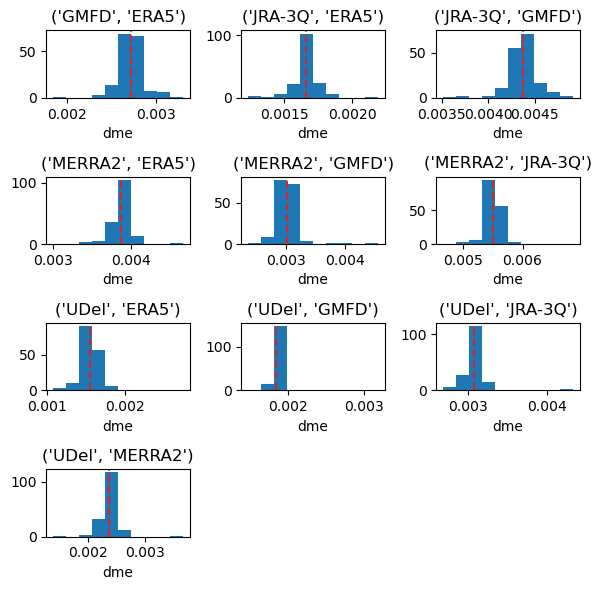

In [145]:
fig = plt.figure(figsize=(6,6))

d_tmp = dmes['gdppc']['dme'].stack(pb = ['proj_base_a','proj_base_b']).dropna('pb')
for pb_idx,pb in enumerate(d_tmp.pb.values):
    ax = plt.subplot(4,3,pb_idx+1)
    d_tmp.sel(pb=pb).plot.hist()
    ax.axvline(d_tmp.sel(pb=pb,loo_id='all'),color='tab:red',linestyle='--')
    ax.set_title(pb)
plt.tight_layout()

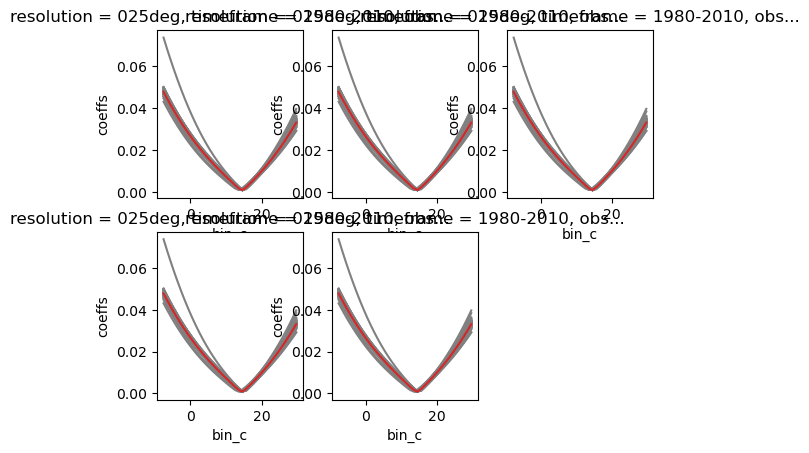

In [146]:
for plt_idx,drop_pb in enumerate(dmgf.proj_base.values):
    ax = plt.subplot(2,3,plt_idx+1)
    for loo_id in dmgf.loo_id.values:
        dmgf.sel(loo_id=loo_id).std('proj_base').coeffs.plot(color='grey')
    dmgf.sel(loo_id='all').std('proj_base').coeffs.plot(color='tab:red')

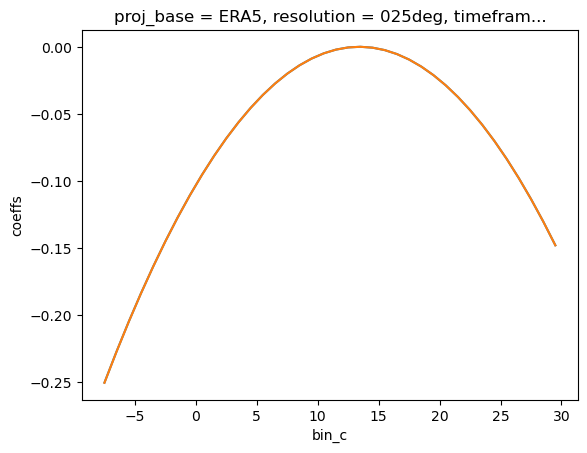

In [147]:
dmgf.sel(proj_base='ERA5',loo_id='all').coeffs.plot()
dmgf.sel(proj_base='ERA5',loo_id=[l for l in dmgf.loo_id.values if l != 'all']).mean('loo_id').coeffs.plot()

<GeoAxes: >

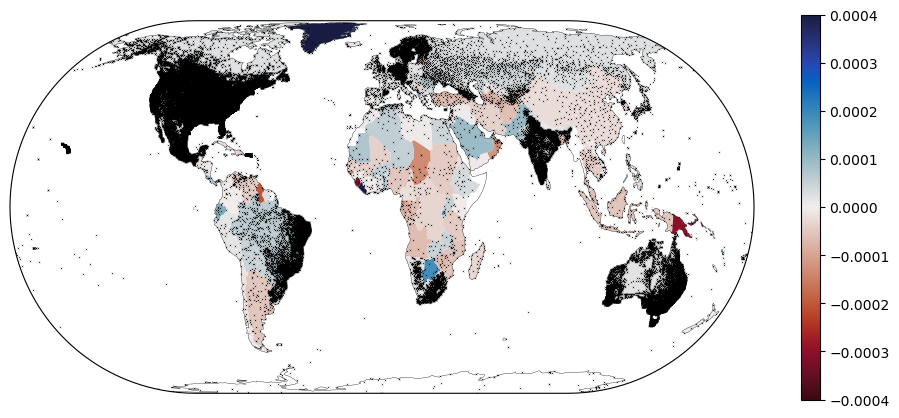

In [151]:
gdf_loo = gdfs['gdppc'].dissolve(by='loo_id')
gdf_loo = gdf_loo.join((dmes['gdppc'] - dmes['gdppc'].sel(loo_id='all'))[['dme_mu','dme_max']].to_dataframe()[['dme_mu','dme_max']],
             how='inner')

fig = plt.figure(figsize=(12,5))
ax = plt.subplot(projection=ccrs.EckertIV())

gdf_loo.plot(column='dme_mu',legend=True,vmin=-0.0004,vmax=0.0004,cmap=cmocean.cm.balance_r,
             ax = ax,transform=ccrs.PlateCarree())
ax.coastlines(linewidth=0.25)

station_locs.plot(ax=ax,transform=ccrs.PlateCarree(),markersize=0.025,marker='x',color='k')


In [108]:
from shapely import Point\

gdf = load_shp('gdppc')

station_locs = pd.read_fwf(
    dir_list['aux']+'ghcnd-stations.txt',
    colspecs=[(0, 11), (11, 20), (20, 30), (30, 37), (37, 71)],
    names=['station_id', 'lat', 'lon', 'elev', 'station_name'],
)
station_locs = gpd.GeoDataFrame(station_locs,
                                geometry = [Point(lon,lat) for lon,lat in zip(station_locs.lon.values,station_locs.lat.values)],
                                crs='EPSG:4326')

# Spatial join: jeder Station das Land zuordnen
joined = gpd.sjoin(station_locs, gdf[['locid', 'SQKM_CNTRY', 'geometry']], 
                   how='inner', predicate='within')

# Stationen pro Land zählen und durch Fläche dividieren
density = (joined.groupby('locid')
                 .agg(n_stations=('station_id', 'count'),
                      area_sqkm=('SQKM_CNTRY', 'first'))
                 .assign(station_density=lambda x: x['n_stations'] / x['area_sqkm']))

# Zurück ins gdf mergen falls gewünscht
gdf = gdf.merge(density, on='locid', how='left')
gdf['station_density'] = gdf['station_density'].fillna(0)

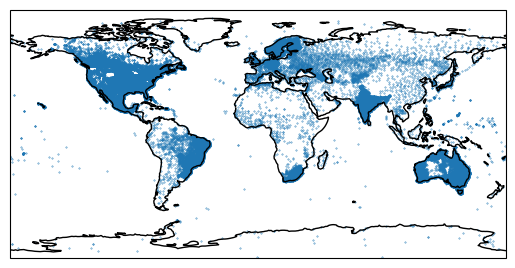

In [122]:
ax = plt.subplot(projection=ccrs.PlateCarree())
station_locs.iloc[0:100000].plot(ax=ax,transform=ccrs.PlateCarree(),markersize=0.1)
ax.coastlines()

### Payroll

In [135]:
gdfs['payroll'] = load_shp('payroll')
gdfs['payroll']['loo_id'] = gdfs['payroll']['locid']
dfr = get_filepaths()
joint_years = [1986,2008]

In [117]:
output_fn = f'{dir_list['proc']}tmp/dmgfdiffs_sources_tmp_payroll.zarr'

if not os.path.exists(output_fn):
    dss = []
    for mod in ['ERA5-025','MERRA2','JRA-3Q','GMFD']:
        print('Processing '+mod+'...')
        dfr_tmp = dfr.query('model == "'+mod+'" and varname == "tasmax" and freq == "day"')
        ds = xr.open_dataset(dfr_tmp.iloc[0]['path'],chunks='auto')
    
        # Subset to joint years
        ds = ds.sel(time=slice(str(joint_years[0]),str(joint_years[1])))
    
        # Aggregate to polygons
        wm = xa.pixel_overlaps(ds,gdfs['payroll'])
        with xa.set_options(impl='numba',silent=True):
            aggs = xa.aggregate(ds.chunk({'lat':-1,'lon':-1}),wm)
    
        aggs = aggs.to_dataset()
        aggs = aggs.set_coords([v for v in aggs if v != 'tasmax'])
        aggs = aggs.expand_dims({'mod':[mod]})
        #aggs = aggs.assign_coords({'poly_idx':aggs.iso+aggs.adm1_id+aggs.adm2_id})
        aggs['poly_idx'] = aggs['locid'].values
        aggs = aggs.drop_vars('locid').rename({'poly_idx':'locid'})
    
        aggs['time'] = pd.date_range(str(joint_years[0])+'-01-01',str(joint_years[1])+'-12-31')
        dss.append(aggs)

    dss = xr.concat(dss,dim='mod',data_vars='different').rename({'mod':'proj_base'})

    # K to F
    dss['tasmax'] = dss['tasmax']*9/5 - 459.67
    # ERA5-025 to ERA5
    dss['proj_base'] = [re.sub(r'\-025','',pb) for pb in dss['proj_base'].values]

    dss.attrs = {'SOURCE':'3b_dmgfdiffs_sources.ipynb',
             'DESCRIPTION':'Max temperature, population for ME comparisons on ADM2 locs'}

    dss = dss.chunk({'proj_base':-1,'time':3650})
    utility_save(dss,output_fn)
else:
    print(output_fn+' exists, loading...')

dss['payroll'] = xr.open_zarr(output_fn)
for v in dss['payroll'].coords:
    dss['payroll'][v] = dss['payroll'][v].load()

dss['payroll']['loo_id'] = (('locid'),dss['payroll']['locid'].values)

/glade/derecho/scratch/schwarzwald/impact_uncertainty/tmp/dmgfdiffs_sources_tmp_payroll.zarr exists, loading...


In [120]:
# Now, get regression coefficients from the leave-one-out regressions
coeffs['payroll'],vcv['payroll'] = coeffs_payroll(get_loos=True,timeframe='ALLYEARS')
coeffs_all,vcv_all = coeffs_payroll(timeframe='ALLYEARS')

# Also add the reference / "all" locations regression
coeffs_all = coeffs_all.expand_dims({'loo_id':['all']})
vcv_all = vcv_all.expand_dims({'loo_id':['all']})

coeffs['payroll'] = xr.concat([coeffs['payroll'],coeffs_all],dim='loo_id')
vcv['payroll'] = xr.concat([vcv['payroll'],vcv_all],dim='loo_id')

coeffs['payroll']['loo_id'] = [k.zfill(5) for k in coeffs['payroll']['loo_id'].values]
coeffs['payroll']['loo_id'] = [re.sub('00all','all',k) for k in coeffs['payroll']['loo_id'].values]

In [122]:
# Ensure that differences between each combination of 
# proj_bases is only done once to avoid double-processing
# (little silly, but gets the job done)
joint_mask = xr.DataArray(0,
                 dims = ['proj_base_a','proj_base_b'],
               coords = {'proj_base_a':(('proj_base_a'),coeffs['payroll'].proj_base.values),
                       'proj_base_b':(('proj_base_b'),coeffs['payroll'].proj_base.values)})
for i in range(joint_mask.sizes['proj_base_a']):
    for j in range(joint_mask.sizes['proj_base_b']):
        if j < i:
            joint_mask[{'proj_base_a':i,'proj_base_b':j}] = 1

keep_pairs = joint_mask.where(joint_mask).stack(pb_pairs = ['proj_base_a','proj_base_b']).dropna(dim='pb_pairs').pb_pairs.values


In [249]:
dmes['payroll'] = np.abs((coeffs['payroll'].coeffs.isel(pred=0).rename({'proj_base':'proj_base_a'}) - 
 coeffs['payroll'].coeffs.isel(pred=0).rename({'proj_base':'proj_base_b'})).
 stack(pb_pairs = ['proj_base_a','proj_base_b']).
 sel(pb_pairs=keep_pairs)).unstack().to_dataset(name='deff')

dmes['payroll']['deff_mu'] = dmes['payroll']['deff'].mean(('proj_base_a','proj_base_b'))
dmes['payroll']['deff_max'] = dmes['payroll']['deff'].max(('proj_base_a','proj_base_b'))

Text(0.5, 1.0, 'Marginal Effects for BHM payroll regression\nwith sample input temperature distribution')

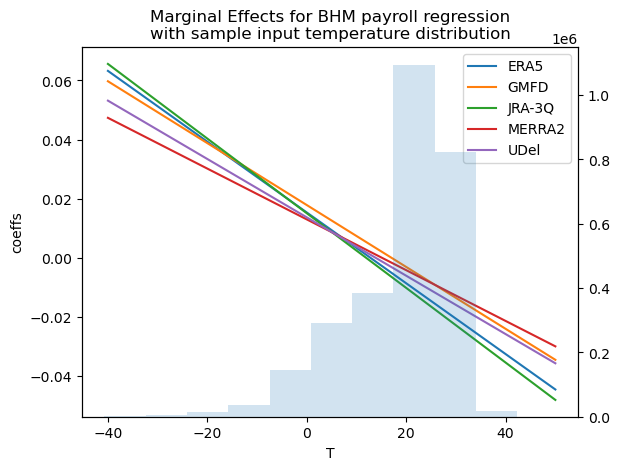

In [273]:
ax = plt.subplot()
for pb in coeffs['gdppc'].proj_base.values:
    mes_gdppc(coeffs['gdppc'].sel(loo_id='all',proj_base=pb),
         xr.Dataset(coords = {'T':(('T'),np.arange(-40,51))})['T']).coeffs.plot(label=pb)
ax.legend()


ax2 = ax.twinx()
dss['gdppc'].sel(proj_base='ERA5').tas.plot.hist(ax=ax2,alpha=0.2)

ax2.set_title('')
ax.set_title('Marginal Effects for BHM payroll regression\nwith sample input temperature distribution')

In [192]:
mes_tmp = mes_gdppc(coeffs['gdppc'].sel(loo_id='all'),dss['gdppc'].tas)
mes_tmp = mes_tmp.load()

In [200]:
np.abs(mes_tmp.sel(proj_base='JRA-3Q') - mes_tmp.sel(proj_base='MERRA2')).coeffs.mean(('time','locid'))

<xarray.DataArray 'coeffs' ()> Size: 8B
array(0.00641415)
Coordinates:
    resolution  <U6 24B '025deg'
    timeframe   <U9 36B '1980-2010'
    obstreat    <U3 12B 'sep'
    loo_id      <U3 12B 'all'

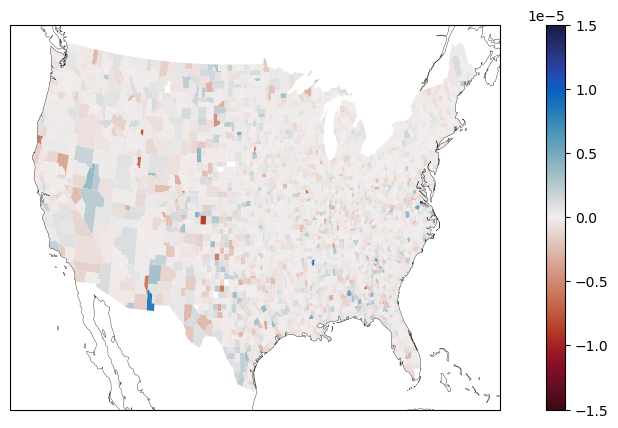

In [250]:
gdf = load_shp('payroll')
gdf['loo_id'] = gdf['locid']
gdf_loo = gdf.set_index('loo_id')
gdf_loo = gdf_loo.join((deffs - deffs.sel(loo_id='00all'))[['deff_mu','deff_max']].to_dataframe()[['deff_mu','deff_max']],
             how='inner')

fig = plt.figure(figsize=(12,5))
ax = plt.subplot(projection=ccrs.AlbersEqualArea(central_longitude=-100,central_latitude=35))

gdf_loo.plot(column='deff_mu',legend=True,vmin=-1.5e-5,vmax=1.5e-5,cmap=cmocean.cm.balance_r,
             ax = ax,transform=ccrs.PlateCarree())
ax.coastlines(linewidth=0.25)

### Joint figure

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/meds_test.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/meds_test.png saved!


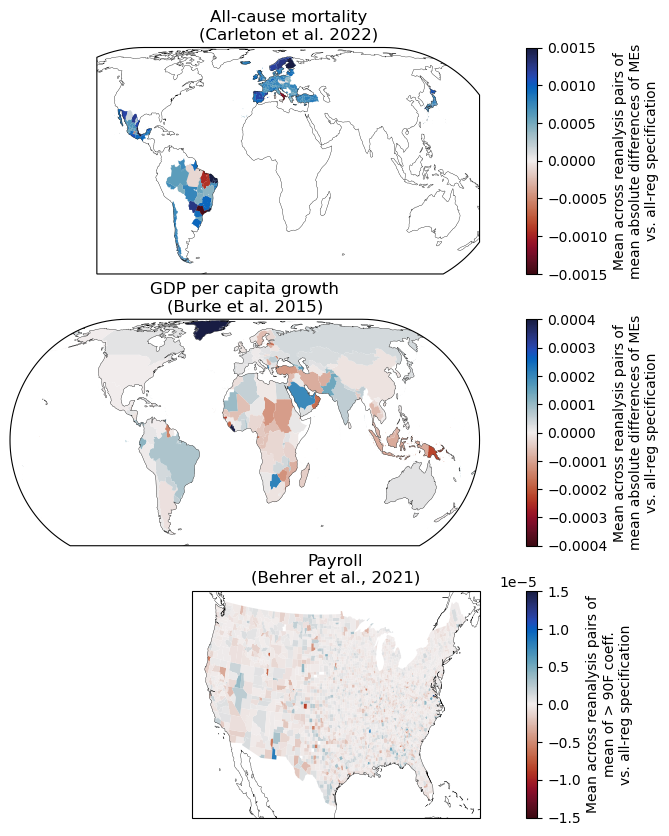

In [208]:
save_fig = True
output_fn = dir_list['figs']+'extra_figs/meds_test'

cbar_params = {'mortality':{'vmin':-0.00150,'vmax':0.00150},
               'gdppc':{'vmin':-0.0004,'vmax':0.0004},
               'payroll':{'vmin':-1.5e-5,'vmax':1.5e-5}}
projs = {'mortality':ccrs.EckertIV(),
         'gdppc':ccrs.EckertIV(),
         'payroll':ccrs.AlbersEqualArea(central_longitude=-100,central_latitude=35)}

proc_full_names = {'mortality':'All-cause mortality\n(Carleton et al. 2022)',
                           'gdppc':'GDP per capita growth\n(Burke et al. 2015)',
                           'payroll':'Payroll\n(Behrer et al., 2021)'}

cbar_labels = {'mortality':'Mean across reanalysis pairs of\nmean absolute differences of MEs\nvs. all-reg specification',
               'gdppc':'Mean across reanalysis pairs of\nmean absolute differences of MEs\nvs. all-reg specification',
               'payroll':'Mean across reanalysis pairs of\nmean of > 90F coeff.\nvs. all-reg specification'} 

vars = {'mortality':'dme_mu',
        'gdppc':'dme_mu',
        'payroll':'deff_mu'}


fig = plt.figure(figsize=(12,10))
for plt_idx,proc in enumerate(dmes):
    ax = plt.subplot(len(dmes),1,plt_idx+1,projection=projs[proc])

    gdf_loo = gdfs[proc].dissolve(by='loo_id')
    gdf_loo = gdf_loo.join((dmes[proc] - dmes[proc].sel(loo_id='all'))[[vars[proc]]].to_dataframe()[[vars[proc]]],
             how='inner')

    gdf_loo.plot(column=vars[proc],legend=True,legend_kwds = {'label':cbar_labels[proc]},
                 vmin=cbar_params[proc]['vmin'],
                 vmax=cbar_params[proc]['vmax'],
                 cmap=cmocean.cm.balance_r,
             ax = ax,transform=ccrs.PlateCarree())
    ax.coastlines(linewidth=0.25)

    ax.set_title(proc_full_names[proc])


if save_fig:
    utility_print(output_fn)


/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/meds_test_raw.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/meds_test_raw.png saved!


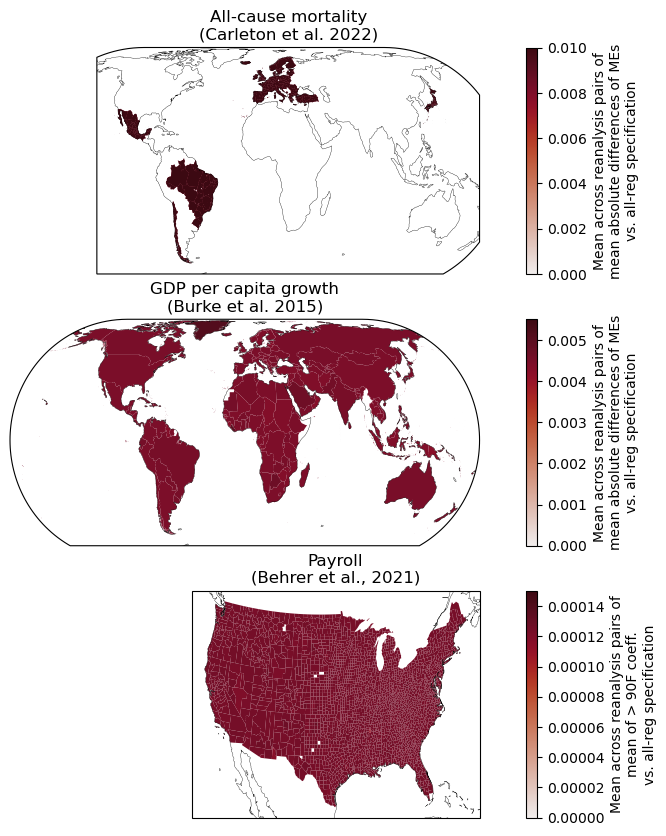

In [261]:
save_fig = True
output_fn = dir_list['figs']+'extra_figs/meds_test_raw'

cbar_params = {'mortality':{'vmin':0,'vmax':0.01},
               'gdppc':{'vmin':0,'vmax':0.0055},
               'payroll':{'vmin':0,'vmax':0.000150}}
projs = {'mortality':ccrs.EckertIV(),
         'gdppc':ccrs.EckertIV(),
         'payroll':ccrs.AlbersEqualArea(central_longitude=-100,central_latitude=35)}

proc_full_names = {'mortality':'All-cause mortality\n(Carleton et al. 2022)',
                           'gdppc':'GDP per capita growth\n(Burke et al. 2015)',
                           'payroll':'Payroll\n(Behrer et al., 2021)'}

cbar_labels = {'mortality':'Mean across reanalysis pairs of\nmean absolute differences of MEs\nvs. all-reg specification',
               'gdppc':'Mean across reanalysis pairs of\nmean absolute differences of MEs\nvs. all-reg specification',
               'payroll':'Mean across reanalysis pairs of\nmean of > 90F coeff.\nvs. all-reg specification'} 

vars = {'mortality':'dme_mu',
        'gdppc':'dme_mu',
        'payroll':'deff_mu'}


fig = plt.figure(figsize=(12,10))
for plt_idx,proc in enumerate(dmes):
    ax = plt.subplot(len(dmes),1,plt_idx+1,projection=projs[proc])

    gdf_loo = gdfs[proc].dissolve(by='loo_id')
    gdf_loo = gdf_loo.join((dmes[proc])[[vars[proc]]].to_dataframe()[[vars[proc]]],
             how='inner')

    gdf_loo.plot(column=vars[proc],legend=True,legend_kwds = {'label':cbar_labels[proc]},
                 vmin=cbar_params[proc]['vmin'],
                 vmax=cbar_params[proc]['vmax'],
                 cmap=cmocean.cm.amp,
             ax = ax,transform=ccrs.PlateCarree())
    ax.coastlines(linewidth=0.25)

    ax.set_title(proc_full_names[proc])


if save_fig:
    utility_print(output_fn)


In [264]:
proc = 'mortality'
gdf_loo = gdfs[proc].dissolve(by='loo_id')
gdf_loo = gdf_loo.join((dmes[proc])[[vars[proc]]].to_dataframe()[[vars[proc]]],
         how='inner')

<Axes: ylabel='Frequency'>

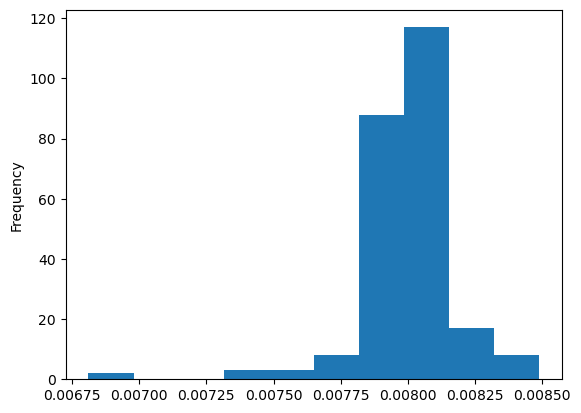

In [269]:
gdf_loo.loc['input']['dme_mu'].plot.hist()

In [244]:
(dmes['mortality'].sel(typ='input').dme_mu.to_dataframe()[['dme_mu']].dropna().sort_values('dme_mu').
 to_csv(dir_list['aux']+'dmes/mean_dmes_mortality.csv'))
(dmes['mortality'].sel(typ='input').dme.to_dataframe()[['dme']].dropna().
 to_csv(dir_list['aux']+'dmes/dmes_mortality.csv'))

In [246]:
(dmes['gdppc'].dme_mu.to_dataframe()[['dme_mu']].dropna().sort_values('dme_mu').
 to_csv(dir_list['aux']+'dmes/mean_dmes_gdppc.csv'))
(dmes['gdppc'].dme.to_dataframe()[['dme']].dropna().sort_values('dme').
 to_csv(dir_list['aux']+'dmes/dmes_gdppc.csv'))

In [252]:
(dmes['payroll'].deff_mu.to_dataframe()[['deff_mu']].dropna().sort_values('deff_mu').
  to_csv(dir_list['aux']+'dmes/mean_deffs_payroll.csv'))
(dmes['payroll'].deff.to_dataframe()[['deff']].dropna().sort_values('deff').
  to_csv(dir_list['aux']+'dmes/deffs_payroll.csv'))

In [251]:
dmes['payroll'].deff.to_dataframe()[['deff']].dropna().sort_values('deff')

,,,deff
loo_id,proj_base_a,proj_base_b,
12047,JRA-3Q,ERA5,1.000000e-07
13307,JRA-3Q,ERA5,1.000000e-07
20199,JRA-3Q,ERA5,1.000000e-07
08105,JRA-3Q,ERA5,1.000000e-07
18115,JRA-3Q,ERA5,1.000000e-07
...,...,...,...
48239,MERRA2,GMFD,2.455000e-04
51181,MERRA2,GMFD,2.456000e-04
48263,MERRA2,GMFD,2.462000e-04


### Various old code?

In [126]:
gdf = gpd.read_file(dir_list['aux']+'geo_data/mortality_insample_world_wadm0.shp')
gdf['poly_idx'] = gdf['iso']+gdf['adm1_id']+gdf['adm2_id']
gdf['regid'] = gdf['adm0']+gdf['adm1_id']

# Fix doubled JPN ones
gdf['poly_idx'] = [re.sub(r'JPN(\d+)', lambda m: f'JPN{m.group(1)[:len(m.group(1))//2]}', s) for s in gdf['poly_idx'].values]

In [ ]:
# Actually I already did this... 

In [ ]:
fn_agg_rea = dir_list['proc']+'aux/tas_day_agg_allreanalyses_insample_impact-regions.zarr'
#ds_aggs = xr.open_zarr(fn_agg_rea)
ds_aggs = dss

ds_aggs = ds_aggs.assign_coords({'regid':(['poly_idx'],ds_aggs['iso'].values+ds_aggs['adm1_id'].values+ds_aggs['adm2_id'].values)})
ds_aggs = ds_aggs.set_index({'poly_idx':'regid'})
ds_aggs['poly_idx'] = ds_aggs['poly_idx'].astype(object)

# ERA5-025 to ERA5
ds_aggs['proj_base'] = [re.sub(r'\-025','',pb) for pb in ds_aggs['proj_base'].values]

In [37]:
# Have to subset by the 
# Get in-sample data that's feeding the regressions
reg_data = pd.read_csv(dir_list['proc']+'reg_inputs/mortality/reginputs_mortality_025deg.csv',low_memory=False,index_col=0)
reg_data = reg_data.query('iso != "IND"')
reg_data = reg_data.query('agegroup == "total"')
reg_data = reg_data.query('obs_mod == "GMFD"')
reg_data['regid'] = reg_data['iso']+reg_data['adm1_id']+reg_data['adm2_id']

In [38]:
reg_data_merge = reg_data[['year','regid','population']]
reg_data_merge = reg_data_merge.query('year >= 1980 & year <= 2010')
reg_data_merge = reg_data_merge.drop_duplicates().set_index(['year','regid'])
reg_data_merge = reg_data_merge.to_xarray().rename({'regid':'poly_idx'}).sel(year = ds_aggs.time.dt.year)
reg_data_merge = reg_data_merge.drop_vars('year')


In [39]:
ds_aggs['population'] = reg_data_merge['population']
ds_aggs['loo_id'] = ds_aggs['adm0']+ds_aggs['adm1_id']

In [40]:
coeffs,vcv = coeffs_mortality(get_loos=True)
coeffs_all,vcv_all = coeffs_mortality()

In [41]:
coeffs_all = coeffs_all.expand_dims({'loo_id':['all']})
vcv_all = vcv_all.expand_dims({'loo_id':['all']})

coeffs = xr.concat([coeffs,coeffs_all],dim='loo_id')
vcv = xr.concat([vcv,vcv_all],dim='loo_id')

What we need is **Integrated Absolute Differences**, which are 

$$d(a,b) = \int|ME_a(T) - ME_b(T)|f_{a\union b}(T)dT$$

where $ME_x(T)$ are the marginal effects (derivative of dose-response function) at temperature T, and $f_{a\union b}(T)$ is the empirical temperature distribution, pooled across the two models' samples "Estimated by Monte-Carlo — a mean over the union of the two sample-temp vectors."

So for Carleton et al., 
$$\begin{aligned}
y(T)&=\sum_k^4\beta_kT^k \\
ME(T) &= \beta_1 + 2\beta_2T + 3\beta_3T^2 + 4\beta_4T^3
\end{aligned}$$

In [42]:
# ACTUALLY NEED TO ALSO REMOVE THE REGION FROM THE ME CALCULATION BELOW
# Also maybe hte move is to make coeffs.coeffs into a dask array with 
# loo_id being the chunk (and full chunks for the other dimensions)

In [43]:
def mes_mortality(coeffs,T):
    me = (coeffs.sel(pred='tassumpoly_1') + 
          2*coeffs.sel(pred='tassumpoly_2')*T + 
          3*coeffs.sel(pred='tassumpoly_3')*(T**2) + 
          4*coeffs.sel(pred='tassumpoly_4')*(T**3))
    return me

In [44]:
def mes_tmp(da,coeff,pop,mean_dim='time'):
    mes = mes_mortality(coeff,da)
    mes = np.abs(mes-mes.rename({'proj_base':'proj_base_1'}))
    mes = (mes*pop).sum('poly_idx')/pop.sum('poly_idx')
    mes = mes.mean(mean_dim)
    print('.',sep='',end='')
    return mes

In [51]:
locids = reg_data[['iso','adm0','adm1_id','adm2_id','regid']].drop_duplicates()
locids['loo_id'] = locids['adm0']+locids['adm1_id']
locids = locids.set_index('regid')['loo_id']

In [58]:
coeffs.loo_id

<xarray.DataArray 'loo_id' (loo_id: 247)> Size: 2kB
array(['AustriaAT1', 'AustriaAT2', 'AustriaAT3', ..., 'United KingdomUKM',
       'United KingdomUKN', 'all'], shape=(247,), dtype=object)
Coordinates:
  * loo_id      (loo_id) object 2kB 'AustriaAT1' 'AustriaAT2' ... 'all'
    resolution  <U6 24B '025deg'
    timeframe   <U9 36B '1980-2010'
    obstreat    <U3 12B 'sep'
    spec        <U6 24B 'pooled'
    indflag     <U5 20B 'noInd'

In [17]:
# Doing it by manually set chunk because dask has major troubles
# doing it itself
chunk_size = 25

## TO-DO: make population 0 in places that are left out before running this
mes = xr.concat([mes_tmp(ds_aggs.tas,coeffs.coeffs.isel(loo_id=slice(idx*chunk_size,(idx+1)*chunk_size)),ds_aggs.population).compute()
                 for idx in np.arange(0,int(coeffs.sizes['loo_id']/chunk_size)+1)],
                dim='loo_id')

.

/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/distributed/client.py:3375: UserWarning: Sending large graph of size 745.13 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


.

/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/distributed/client.py:3375: UserWarning: Sending large graph of size 745.13 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


.

...

/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/distributed/client.py:3375: UserWarning: Sending large graph of size 745.13 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


.

/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/distributed/client.py:3375: UserWarning: Sending large graph of size 745.13 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


.

/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/distributed/client.py:3375: UserWarning: Sending large graph of size 745.13 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [18]:
mes = mes.where(mes!=0)

In [77]:
mes.attrs = {'SOURCE':'3b_dmgfdiffs_sources.ipynb',
             'DESCRIPTION':'differences between marginal effects of Carleton et al. mortality damage function, with MEs evaluated at (pop-weighted) temperatures of forcing dataset'} 
mes.to_netcdf(dir_list['aux']+'mes_mortality_tmp.nc')

In [21]:
mes = xr.open_dataset(dir_list['aux']+'mes_mortality_tmp.nc')
mes = mes['__xarray_dataarray_variable__']

In [22]:
mmes = mes.mean(('proj_base','proj_base_1'))

In [23]:
dmmes = (mmes - mmes.sel(loo_id = 'all'))

In [24]:
df_regs = reg_data[['iso','adm0','adm1_id','adm2_id']].drop_duplicates()
df_regs['loo_id'] = df_regs['adm0']+df_regs['adm1_id']

In [25]:
gdf = gpd.read_file(dir_list['aux']+'geo_data/mortality_insample_world.shp')
gdf = gdf.query('iso != "IND" and iso != "USA" and iso != "CHN"')
gdf['geometry'] = gdf.make_valid()
gdf = gdf.to_crs('EPSG:4326')
gdf = gdf.set_index(['iso','adm1_id','adm2_id']).join(df_regs.set_index(['iso','adm1_id','adm2_id'])['loo_id'])
#gdf = gdf.reset_index().dropna().set_index('loo_id').join(dmmes.to_dataframe(name='dmme')[['dmme']])
gdf = gdf.reset_index().dropna().set_index('loo_id').join(dmmes.to_dataframe(name='dmme')[['dmme']])

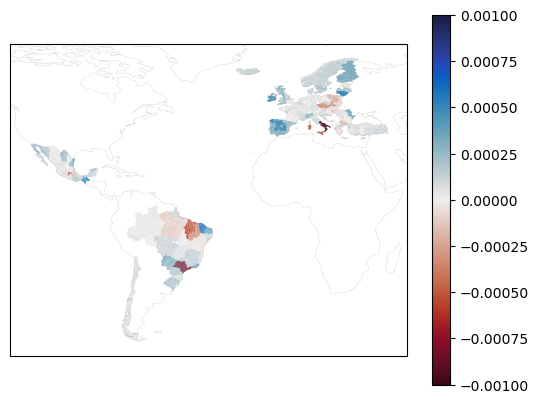

In [26]:
ax = plt.subplot(projection=ccrs.PlateCarree())
gdf.plot(column='dmme',legend=True,cmap=cmocean.cm.balance_r,vmin=-0.001,vmax=0.001,ax=ax,transform=ccrs.PlateCarree())
ax.coastlines(linewidth=0.05)

In [27]:
from funcs_support import load_shp
gdf_impact = load_shp('mortality')

#--------------------------------------
# Get sample future exposure
#--------------------------------------
# Now, get tasbinC for one random BCD-ME member, as illustration
fn = glob.glob(dir_list['bcd_me']+'/*qdm-qplad*CanESM5*')[0]
with warnings.catch_warnings():
    warnings.filterwarnings('ignore')
    ds_bcd = xr.open_zarr(fn,decode_timedelta=False,consolidated=False)
has_data = ds_bcd.has_data.sel(gwl=2,variable='tasbinC').load()
has_data = np.where(has_data)[0]
ds_bcd = ds_bcd.isel(idv = has_data[0])['tasbinC']
ds_bcd = ds_bcd.sel(gwl=[0.61,2])

wm = xa.pixel_overlaps(ds_bcd,gdf_impact)
with xa.set_options(impl='numba',silent=True):
    agg_bcd = xa.aggregate(ds_bcd.chunk({'lat':-1,'lon':-1}),wm)
agg_bcd = agg_bcd.to_dataset()

creating polygons for each pixel...
lat/lon bounds not found in dataset; they will be created.
calculating overlaps between pixels and output polygons...
success!


/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/distributed/client.py:3375: UserWarning: Sending large graph of size 2.31 GiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [46]:
mes_future = mes_tmp(agg_bcd.binC,
        coeffs.coeffs.chunk({'loo_id':1}),
        agg_bcd.tasbinC.sel(gwl=2).chunk(),
       mean_dim='binC')
mes_future = mes_future.compute()
mes_future = mes_future.where(mes_future != 0)

.

/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/distributed/client.py:3375: UserWarning: Sending large graph of size 54.56 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [46]:
mes_future = mes_mortality(coeffs,agg_bcd.binC)
mes_future = np.abs(mes_future-mes_future.rename({'proj_base':'proj_base_1'}))

In [50]:
(mes_future*agg_bcd.tasbinC.sel(gwl=2,proj_base='ERA5').chunk()).suM('

<xarray.Dataset> Size: 56GB
Dimensions:      (proj_base: 4, loo_id: 247, binC: 73, proj_base_1: 4,
                  poly_idx: 24377)
Coordinates:
  * proj_base    (proj_base) <U6 96B 'ERA5' 'GMFD' 'JRA-3Q' 'MERRA2'
  * loo_id       (loo_id) object 2kB 'AustriaAT1' 'AustriaAT2' ... 'all'
  * binC         (binC) float64 584B -21.0 -20.0 -19.0 -18.0 ... 49.0 50.0 51.0
  * proj_base_1  (proj_base_1) <U6 96B 'ERA5' 'GMFD' 'JRA-3Q' 'MERRA2'
  * poly_idx     (poly_idx) int64 195kB 0 1 2 3 4 ... 24373 24374 24375 24376
    resolution   <U6 24B '025deg'
    timeframe    <U9 36B '1980-2010'
    obstreat     <U3 12B 'sep'
    spec         <U6 24B 'pooled'
    indflag      <U5 20B 'noInd'
    gwl          float64 8B 2.0
Data variables:
    coeffs       (loo_id, proj_base, binC, proj_base_1, poly_idx) float64 56GB dask.array<chunksize=(247, 4, 73, 4, 24377), meta=np.ndarray>


In [37]:
mes_future = (mes_future.chunk(loo_id=1)*agg_bcd.tasbinC.sel(gwl=2,proj_base='ERA5').chunk()).sum('binC')/agg_bcd.tasbinC.sel(gwl=2,proj_base='ERA5').sum('binC')



In [38]:
mes_future = mes_future.compute()

/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/distributed/client.py:3375: UserWarning: Sending large graph of size 179.77 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
2026-05-06 09:51:32,489 - distributed.worker.memory - WARNING - Worker is at 85% memory usage. Pausing worker.  Process memory: 13.73 GiB -- Worker memory limit: 16.00 GiB
2026-05-06 09:51:32,607 - distributed.nanny - WARNING - Restarting worker
2026-05-06 09:51:32,711 - distributed.worker.memory - WARNING - Worker is at 83% memory usage. Pausing worker.  Process memory: 13.44 GiB -- Worker memory limit: 16.00 GiB
2026-05-06 09:51:32,937 - distributed.nanny - WARNING - Restarting worker
2026-05-06 09:51:34,881 - distributed.nanny - WARNING - Restarting w

KilledWorker: Attempted to run task ('sum-sum-aggregate-cc144a9e985395e3d0851045944c7eb4', 1, 0, 0, 0) on 4 different workers, but all those workers died while running it. The last worker that attempt to run the task was tcp://127.0.0.1:46177. Inspecting worker logs is often a good next step to diagnose what went wrong. For more information see https://distributed.dask.org/en/stable/killed.html.

In [40]:
mes_future

<xarray.Dataset> Size: 771MB
Dimensions:      (proj_base: 4, loo_id: 247, proj_base_1: 4, poly_idx: 24377)
Coordinates:
  * proj_base    (proj_base) <U6 96B 'ERA5' 'GMFD' 'JRA-3Q' 'MERRA2'
  * loo_id       (loo_id) object 2kB 'AustriaAT1' 'AustriaAT2' ... 'all'
  * proj_base_1  (proj_base_1) <U6 96B 'ERA5' 'GMFD' 'JRA-3Q' 'MERRA2'
  * poly_idx     (poly_idx) int64 195kB 0 1 2 3 4 ... 24373 24374 24375 24376
    resolution   <U6 24B '025deg'
    timeframe    <U9 36B '1980-2010'
    obstreat     <U3 12B 'sep'
    spec         <U6 24B 'pooled'
    indflag      <U5 20B 'noInd'
    gwl          float64 8B 2.0
Data variables:
    coeffs       (loo_id, proj_base, proj_base_1, poly_idx) float64 771MB dask.array<chunksize=(1, 4, 4, 24377), meta=np.ndarray>

In [39]:
agg_bcd.tasbinC.sel(gwl=2,proj_base='ERA5')

<xarray.DataArray 'tasbinC' (poly_idx: 24377, binC: 73)> Size: 14MB
array([[17.64927584,  2.85      ,  3.44977718, ...,  0.        ,
         0.        ,  0.        ],
       [15.        ,  1.8       ,  2.85      , ...,  0.        ,
         0.        ,  0.        ],
       [ 5.4       ,  1.8       ,  1.6       , ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ]], shape=(24377, 73))
Coordinates:
  * poly_idx   (poly_idx) int64 195kB 0 1 2 3 4 ... 24373 24374 24375 24376
  * binC       (binC) float64 584B -21.0 -20.0 -19.0 -18.0 ... 49.0 50.0 51.0
    proj_base  <U6 24B 'ERA5'
    gwl        float64 8B 2.0

In [6]:
dmgfs = load_dmgfs('mortality',load_kwargs = {'get_loos':True})

In [27]:
dmgfs.isel(loo_id = 0).mean('sidx').std('proj_base').sel(Tref=slice(0,20)).plot()

NameError: name 'dmgfs' is not defined

In [18]:
#coeffs,vcv = coeffs_mortality(get_loos = True)
#ts = np.arange(-20,51,0.25)
#var_stem = 'tassumpoly_'
#poly_degs = [int(re.split(var_stem,v)[-1]) for v in coeffs.pred.values if var_stem in v]
#t_vals = xr.DataArray(np.vstack([ts**k for k in poly_degs]),
#             dims = ['pred','bin_c'],
#             coords = {'pred':[v for v in coeffs.pred.values if var_stem in v],
#                       'bin_c':ts})

# Get damage function
#dmgf = (coeffs*t_vals).sum('pred')

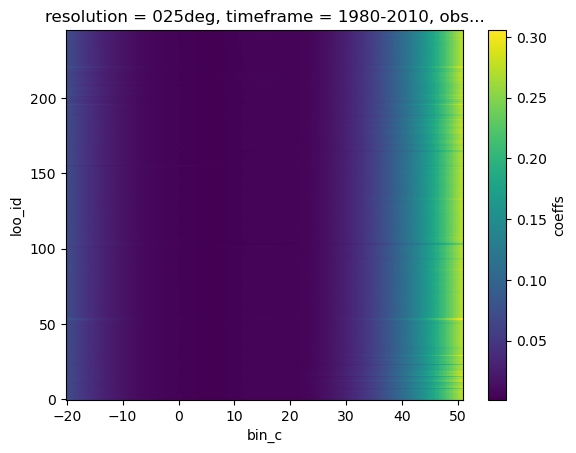

In [4]:
dmgf.differentiate('bin_c').std('proj_base').coeffs.reset_index('loo_id',drop=True).plot()